# DATA3320 Week 8 — Class Demo 2
## Machine Learning Basics: Training, Prediction, and Evaluation

**Primary emphasis: theory and interpretation first; examples and code second**

> **Dataset:** We continue with the same [Wk8_ClassDemo_health_data.csv](https://raw.githubusercontent.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/refs/heads/main/data/Wk8_ClassDemo_health_data.csv)

Click the link above to download the dataset used in Class Demo 1. It contains **65,000 fully synthetic records**. It contains no real patient information and must not be interpreted as clinical evidence or medical advice.

### Learning outcomes
By the end of this class, students should be able to:

1. explain the purpose of training and test data;
2. distinguish an algorithm, a fitted model, and a prediction;
3. explain what `.fit()` and `.predict()` represent conceptually;
4. describe actual values, predicted values, and residual/prediction error;
5. explain MAE, RMSE, and R² in plain language;
6. compare models using held-out information;
7. explain why more features do not guarantee a better model;
8. explain the basic purpose of encoding a categorical variable;
9. recognize overfitting from a train-versus-test performance gap;
10. communicate model results without overstating what the model proves.

### Today's guiding question

> **How do we teach a model using historical data, and how do we decide whether its predictions are useful on data it did not learn from?**


## 📚 Week 8 Learning Resources

This notebook supports the Week 8 learning materials. Review the resources below before and after completing this class demo.

#### Lecture 14 – Machine Learning Basics
- [Recording](https://nait.video.yuja.com/V/Video?v=1347397&node=7565700&a=455105452)
- [Lecture 14 Presentation](https://lms.nait.ca/d2l/le/lessons/182236/topics/6115764)

- [Lecture 13-14 Intro ML Notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture13-14_Intro_ML.ipynb)

#### Lecture 14 Workbook
- [Workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture14_workbook.ipynb)
- [Solution](https://colab.research.google.com/drive/1BBPZTAtLJRfom4zewxU-2pGe8cKqv9Yv?usp=sharing)

### 🧪 Assignment

#### Machine Learning Assignment 1
- [Assignment Submission Folder](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551188)
- [Assignment Walkthrough Recording](https://nait.video.yuja.com/V/Video?v=1347404&node=7565707&a=124245085)

### 📖 Required Reading

#### Machine Learning with Python
- [O'Reilly Online Book](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)

Read:

- Chapter 4 — Predicting Numerical Values: Getting Started with Regression



<details>
<summary>📝 Note</summary>

**0–5 min | Set the frame.** Remind students that Class Demo 1 stopped after defining `X` and `y`. Today's goal is not to memorize scikit-learn syntax. Every code block corresponds to a conceptual step: split → fit → predict → compare → evaluate.

</details>


## 1. Review: Where Are We in the Machine-Learning Lifecycle?

In Class Demo 1 we established:

- **observation** = one historical case;
- **features (`X`)** = information provided to the model;
- **target (`y`)** = outcome we want to predict;
- **algorithm** = learning method;
- **model** = result after the algorithm learns from training data;
- **prediction** = model's estimate for an observation.

The broader workflow is:

```text
Define problem
      ↓
Understand data
      ↓
Choose features + target
      ↓
Split historical data
      ↓
Train model
      ↓
Predict held-out cases
      ↓
Evaluate prediction errors
      ↓
Use carefully on new cases
```

Today begins at **split historical data**.


<details>
<summary>📝 Note</summary>

**Theory emphasis — lifecycle retrieval.** Before showing the workflow, ask students to reconstruct as much of it as possible from Class 1. Use the board to separate three ideas students often collapse together: **data preparation**, **model learning**, and **model evaluation**. Ask: “If we already have `X` and `y`, has machine learning happened yet?” Expected answer: not yet; we have defined the learning problem but have not fitted a model.

**Likely misconception:** students may say `X` is “the training data.” Correct this gently: `X` is the full selected feature matrix at this point. Only after splitting do we have `X_train` and `X_test`.

**Teaching cue:** repeatedly point to the current lifecycle stage as the class progresses. The intent is for students to see the Python lines as implementations of an already understood workflow.

</details>


### 🧠 Check-In 1

Before running any model, answer:

1. What is the target in our class problem?
2. What does one row represent?
3. Why is `patient_id` not part of our initial feature set?
4. Is the task regression or classification?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 1 — Expected Answer</summary>

1. `health_cost`.
2. One synthetic health record.
3. `patient_id` is an identifier rather than an intended predictive health measurement.
4. **Regression**, because `health_cost` is numerical.

</details>


<details>
<summary>📝 Note</summary>

**5–15 min | Retrieval practice.** Let students answer without opening Class Demo 1. Correct feature/target confusion before proceeding. The rest of today's workflow depends on that distinction.

</details>


## 2. Why Do We Split Historical Data?

Suppose a student receives the exact questions and answers before an exam and then takes that same exam. A high score would not provide strong evidence that the student can solve **new** questions.

A similar problem occurs if we judge a model only on the same observations it used to learn.

### Training set

The **training set** is the portion of historical data used by the algorithm to estimate the model.

For each training observation we provide:

**features + known target**

### Test set

The **test set** is held back from model fitting. After the model has been trained, we provide only the test features to the model, obtain predictions, and then compare those predictions with the known test targets.

The target is known to **us** because the test observations are historical, but the target is not supplied to the model when it predicts.

### Why this matters

The purpose is to create a simple simulation of future prediction:

```text
TRAINING
X_train + y_train
        ↓
      fit
        ↓
      model

TESTING
X_test only
    ↓
  model
    ↓
predictions
    ↓
compare with y_test
```

This helps us ask a much more useful question:

> **Can the model make reasonable predictions for observations it did not use for learning?**


<details>
<summary>📝 Note</summary>

**Theory emphasis — generalization before syntax.** Do not introduce `train_test_split()` until students can explain why a test set exists. Use the exam analogy, then ask for a second analogy from the class. A useful prompt is: “Would you trust a chef assessment if the chef practiced the exact dish with the judge immediately beforehand?”

**Board sketch:** draw one large box labelled “historical labelled data,” then divide it into a large Training box and a smaller Test box. Write `X + y` inside both boxes, then cross out `y_test` only at the moment of prediction. Explain that `y_test` still exists for us as evaluators.

**Key distinction to reinforce:** the test set is not “future data.” It is historical data deliberately treated as unseen for evaluation. It simulates the information constraint of future prediction.

**Check for understanding:** ask three students separately: “What does the model see during fitting?”, “What does the model see during test prediction?”, and “What do we use after prediction to score the model?”

</details>


### 80/20 Split

For today's demonstration, we use:

- **80% training data**
- **20% test data**

With 65,000 records, that produces:

- 52,000 training observations
- 13,000 test observations

The 80/20 choice is a teaching choice, not a universal law. The important principle is that the test observations are kept separate from model fitting.

### What does `random_state=42` mean?

The split is random. Setting `random_state=42` makes the random split reproducible so that everyone running the notebook receives the same training and test rows. The number 42 does **not** make the model more accurate.


### Reproducibility Is Not the Same as Robustness

Using `random_state=42` gives us **reproducibility**: another student running the same code on the same dataset can obtain the same split.

However, one reproducible split does not prove that the model would produce exactly the same performance metrics under every possible split of the data.

This distinction is useful:

- **Reproducibility:** can we repeat the same analysis and obtain the same result?
- **Robustness of evaluation:** do our conclusions remain reasonably stable when evaluation conditions change?

Today we use one fixed 80/20 split because it keeps the basic workflow easy to understand.

Later, a common extension is **cross-validation**, where a model is evaluated across multiple partitions of the data rather than relying on only one train/test split. We are introducing the term only as a preview; we will not implement cross-validation today.


<details>
<summary>📝 Note</summary>

**Misconception check:** ask whether `random_state=42` proves that 42 is the best split or produces the best model. Expected: no. It makes today's demonstration repeatable. Mention cross-validation only as a future method for broader evaluation.

**15–30 min.** Spend time here. Draw train and test boxes. Ask, “Does the model see `y_test` when making predictions?” The expected answer is no. Then ask why *we* still keep `y_test`: so we can evaluate predictions after they are produced.

</details>


### 🧠 Check-In 2

With 65,000 observations and a 20% test set:

1. How many observations should be used for training?
2. How many should be used for testing?
3. What information does the model use during training?
4. Why do we keep `y_test` if the model does not receive it during prediction?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 2 — Expected Answer</summary>

1. 52,000 training observations.
2. 13,000 test observations.
3. The model learns from `X_train` and `y_train`.
4. We keep `y_test` so that **after** predictions are produced, we can compare predictions with the known historical outcomes and measure performance.

</details>


## 3. Load the Same Dataset and Rebuild `X` and `y`

The Python is intentionally simple. It translates the concepts from Class Demo 1 into objects that scikit-learn can use.


<details>
<summary>📝 Note</summary>

**Theory-to-code bridge.** Keep this section brief because the concepts were established in Class 1. Ask students to narrate each object before running the code: `health` is the full table; `X` contains selected features; `y` contains the target.

**Before running the split:** have students calculate 80% and 20% of 65,000 without Python. Then predict the four shapes. This makes `.shape` a verification step rather than a mysterious output.

**Important:** explain that five columns in `X_train` and `X_test` do not mean five records; they mean five selected features for every record.

</details>


In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

health = pd.read_csv('Wk8_ClassDemo_health_data.csv')

features = [
    'age',
    'bmi',
    'systolic_bp',
    'exercise_hours',
    'sleep_hours'
]

X = health[features]
y = health['health_cost']

print('X:', X.shape)
print('y:', y.shape)

X: (65000, 5)
y: (65000,)


In [124]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print('X_train:', X_train.shape)
print('X_test: ', X_test.shape)
print('y_train:', y_train.shape)
print('y_test: ', y_test.shape)

X_train: (52000, 5)
X_test:  (13000, 5)
y_train: (52000,)
y_test:  (13000,)


<details>
<summary>📝 Note</summary>

**30–38 min.** Before running the split cell, ask students to predict all four shapes. After running it, connect 5 columns to the five selected features and 52,000/13,000 rows to the 80/20 split.

</details>


## 4. What Does It Mean to “Fit” a Model?

We will use **linear regression** as our first machine-learning algorithm.

At an introductory level, think of linear regression as an algorithm that attempts to estimate a numerical target by learning how feature values are associated with that target.

### Creating an algorithm object is not learning

```python
model = LinearRegression()
```

This creates an unfitted model object. It has not learned the relationships in our dataset yet.

### `.fit()` is the learning step

```python
model.fit(X_train, y_train)
```

During `.fit()`, the algorithm examines the training features and their known targets and estimates coefficients that define a fitted linear model.

Conceptually:

```text
X_train + y_train
        ↓
LinearRegression algorithm
        ↓
learn relationships
        ↓
fitted model
```

### Model versus algorithm

This distinction from Class Demo 1 now becomes concrete:

- `LinearRegression` describes the **algorithm/model type**.
- `model` after `.fit()` contains values learned from **our training data**.


<details>
<summary>📝 Note</summary>

**Theory emphasis — fitting is estimation, not memorized syntax.** Say aloud: “Fit means use training examples to estimate the model’s parameters.” Students do not need coefficient mathematics yet, but they should know that the fitted object now contains information learned from the training data.

**Three-stage verbal routine:**
1. Create: choose the model type.
2. Fit: learn from `X_train` and `y_train`.
3. Use: apply the fitted model to feature rows.

**Likely misconception:** `LinearRegression()` by itself has not learned anything. Ask students to predict what would happen conceptually if we tried to make meaningful predictions before fitting.

**Optional board connection:** relate linear regression to the familiar idea of a line of best fit, then explain that several features mean the fitted relationship is no longer just a single 2D line. Keep the mathematics light unless students ask.

</details>


### What Is Linear Regression Trying to Learn?

Linear regression predicts a numerical target by learning a **weighted combination of feature values**.

With one feature, the basic idea can be written as:

$$\hat{y}=b_0+b_1x$$

where:

- $\hat{y}$ is the predicted target;
- $b_0$ is the **intercept**;
- $b_1$ is the learned **coefficient** for the feature;
- $x$ is the feature value.

With several features, the same idea expands to:

$$\hat{y}=b_0+b_1x_1+b_2x_2+\cdots+b_px_p$$

For our five-feature model, the algorithm estimates an intercept and one coefficient for each selected feature.

### Intercept

The intercept is the model's baseline mathematical component when all included feature values are zero. Its practical interpretation may or may not be meaningful when zero is outside the realistic range of the features.

### Coefficient

A coefficient represents how the fitted prediction changes with a one-unit change in that feature **while the other included features are held constant**.

This is an association inside the fitted model. A coefficient does **not** by itself prove that changing the feature will cause the target to change.

### What `.fit()` does here

We do not calculate the coefficients manually. `model.fit(X_train, y_train)` estimates the intercept and coefficients from the training data.


<details>
<summary>📝 Note</summary>

**Linear-regression teaching move:** Draw a simple one-feature scatter plot and a line through it. Label the vertical prediction from the line. Then say that with five features, the same weighted-combination idea operates in more dimensions and is difficult to draw on a 2D board. Avoid coefficient arithmetic unless students need it. Reinforce that coefficient interpretation is conditional on the other included features and is not a causal statement.

</details>


### Parameters vs. Hyperparameters

Two words appear often in machine learning:

- **Parameters** are values learned from the training data during `.fit()`. In linear regression, the fitted intercept and coefficients are model parameters.
- **Hyperparameters** are settings chosen before fitting that control some aspect of the learning algorithm or model structure.

Our basic `LinearRegression()` example does not require us to tune a major complexity setting. Later in this notebook, the decision-tree demonstration uses `max_depth`. That is an example of a **hyperparameter** because we choose it rather than learn it directly as a fitted coefficient from the data.

The key distinction is:

> **parameters are learned; hyperparameters are set before learning.**


<details>
<summary>📝 Note</summary>

**Keep this vocabulary brief.** Ask: “Who chooses a hyperparameter: the fitting process or the modeller?” Then ask: “Who determines a fitted coefficient: us manually or `.fit()` from the data?” Do not introduce tuning procedures yet.

</details>


In [132]:
model = LinearRegression()
model.fit(X_train, y_train)

print('The model has been fitted using the training data.')

The model has been fitted using the training data.


### 🧠 Check-In 3

Immediately after `model = LinearRegression()` but before `.fit()`:

1. Has the model learned from our health dataset?
2. What two objects are supplied to `.fit()`?
3. Why do we use training data rather than test data in `.fit()`?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 3 — Expected Answer</summary>

1. **No.** The object exists, but it has not learned from the dataset.
2. `X_train` and `y_train`.
3. The test observations are intentionally held back so they can later provide evidence about performance on observations not used for fitting.

</details>


<details>
<summary>📝 Note</summary>

**38–50 min.** Pause on `.fit()`. Students often treat it as magic syntax. Ask them to narrate it: “Use these training features and known training targets to estimate a model.” Do not teach coefficient mathematics unless needed by the course sequence.

</details>


## 5. What Does `.predict()` Do?

After fitting, the model can be given feature rows and asked to estimate the target.

```python
predictions = model.predict(X_test)
```

Notice what is **not** inside `.predict()`:

`y_test`

The model receives the test **features** and returns predicted target values.

Only after the predictions exist do we compare them with the actual historical test targets.

### Actual versus predicted

For a held-out historical observation:

- **Actual** = the recorded `health_cost` in `y_test`.
- **Predicted** = the value returned by the fitted model.

A difference is expected. Machine learning produces estimates, not guaranteed exact answers.


<details>
<summary>📝 Note</summary>

**Theory emphasis — inference is different from learning.** `.predict()` does not retrain or update the model. It applies the relationship learned during `.fit()` to new feature rows.

**Pause before execution:** write `model.predict( ? )` on the board and ask whether the blank should contain `X_test`, `y_test`, or both. Require a reason, not only the correct object name.

**Use one-row narration:** after displaying results, choose one row and say: “For this held-out record, the actual historical target was ___ and the model estimated ___.” Ask students which number was available to the model at prediction time.

**Misconception check:** predicted values differing from actual values are not Python errors. They are prediction errors to be evaluated.

</details>


In [138]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    'Actual Cost': y_test.values,
    'Predicted Cost': predictions
})

results.head(10)

,Actual Cost,Predicted Cost
0,4955,6663.668112
1,9497,7728.077329
2,5890,6019.765373
3,6144,6956.406053
4,4818,6113.819401
5,5912,6445.357634
6,2731,4945.833703
7,8897,7624.161695
8,8919,6498.139986
9,5958,5384.142945


### 🧠 Check-In 4

Look at the first several rows.

1. Are actual and predicted costs identical?
2. Does a difference automatically mean the model failed?
3. Which quantity did the model actually receive when generating these predictions: `X_test` or `y_test`?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 4 — Expected Answer</summary>

1. No; predicted values generally differ from actual values.
2. No. Predictions are estimates. We need evaluation metrics to summarize how large the errors are across many observations.
3. The model received `X_test`. `y_test` is used afterward for evaluation.

</details>


<details>
<summary>📝 Note</summary>

**50–60 min.** Select one displayed row and have a student read it aloud as “actual was ___; predicted was ___.” Do not label the model good or bad yet. Ask: “What evidence would we need before making that judgment?”

</details>


## 6. Prediction Error: The Foundation of Evaluation

Before learning metric names, understand the basic idea of error.

For one observation, we can define:

> **error = actual − predicted**

If actual cost is `$7,200` and predicted cost is `$6,900`:

`error = 7200 - 6900 = 300`

If actual cost is `$7,200` and predicted cost is `$7,500`:

`error = 7200 - 7500 = -300`

The sign tells us the **direction** of the miss under this definition.

### Why not simply average signed errors?

Positive and negative errors can cancel. A model could make some large under-predictions and some large over-predictions but still have an average signed error near zero.

That is why evaluation metrics transform errors before summarizing them.


<details>
<summary>📝 Note</summary>

**Theory emphasis — direction versus magnitude.** Explain that signed error answers “in which direction did we miss?” while absolute error answers “how far away were we?” This prepares students for MAE.

**Work two manual examples first:** one under-prediction and one over-prediction of the same magnitude. Ask students to compute the two signed errors and then their average. The cancellation demonstrates why an average signed error can be misleading.

**Vocabulary:** you may mention that “residual” is commonly used for a difference between observed and fitted/predicted values, but keep the class terminology consistent with **prediction error** today.

**Do not rush to metrics:** students should understand why we need a summary measure before seeing MAE/RMSE formulas or code.

</details>


In [144]:
results['Error'] = results['Actual Cost'] - results['Predicted Cost']
results['Absolute Error'] = results['Error'].abs()
results.head(10)

,Actual Cost,Predicted Cost,Error,Absolute Error
0,4955,6663.668112,-1708.668112,1708.668112
1,9497,7728.077329,1768.922671,1768.922671
2,5890,6019.765373,-129.765373,129.765373
3,6144,6956.406053,-812.406053,812.406053
4,4818,6113.819401,-1295.819401,1295.819401
5,5912,6445.357634,-533.357634,533.357634
6,2731,4945.833703,-2214.833703,2214.833703
7,8897,7624.161695,1272.838305,1272.838305
8,8919,6498.139986,2420.860014,2420.860014
9,5958,5384.142945,573.857055,573.857055


### 🧠 Check-In 5

Why can the simple average of signed errors be misleading?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 5 — Expected Answer</summary>

Because positive and negative errors can cancel each other. A model could make substantial errors in both directions while the average signed error appears close to zero.

</details>


### Before Metrics: What Is a Simple Baseline?

Model performance is easier to understand when we have something simple to compare against.

Imagine ignoring all five features and predicting the **same value for every test observation**. For a basic regression baseline, that value could be the average target observed in the training data.

This baseline does not learn relationships between age, BMI, blood pressure, exercise, sleep, and cost. It simply asks:

> **What if we always made one simple prediction?**

A useful predictive model should ideally provide information beyond such a simple strategy.

This baseline idea is especially helpful when interpreting R², because R² compares the fitted model with a simple reference based on predicting the mean target.


<details>
<summary>📝 Note</summary>

**Baseline demonstration without extra code:** ask students, “If we refused to look at any features, what single number might we predict for everyone?” Guide them to the training-target mean. Then ask why a model using features should ideally beat that simple strategy. This gives R² a conceptual anchor before its definition.

</details>


## 7. Three Regression Evaluation Metrics

We will use three common regression metrics. The goal today is **interpretation**, not memorizing formulas.

### MAE — Mean Absolute Error

MAE asks:

> **On average, how large are the absolute prediction errors?**

Because absolute values remove the sign, over-predictions and under-predictions do not cancel.

MAE uses the **same units as the target**. If the target is measured in dollars, MAE is also measured in dollars.

For models evaluated on the same target and same test observations, **lower MAE means smaller average absolute errors**.

### RMSE — Root Mean Squared Error

RMSE also summarizes prediction error in the target's units, but it squares individual errors before averaging and then takes a square root.

The practical effect is:

> **Larger errors receive more influence in RMSE than in MAE.**

For comparable models, lower RMSE is preferred.

### R² — Coefficient of Determination

R² provides a different view. It describes how much of the variability in the target is captured by the model relative to a simple baseline.

A higher R² generally indicates that the model captures more of the target's variation on the evaluated data.

However:

> **Do not judge a model from R² alone.**

Use R² together with an error metric and the context of the prediction problem.


<details>
<summary>📝 Note</summary>

**This is the main conceptual segment of Class 2.** Spend more time on meaning than calculation. Write three questions on the board:
- MAE: “How far off are we on average?”
- RMSE: “What if we want larger misses to matter more?”
- R²: “How much variation does the model capture relative to a baseline?”

**MAE teaching move:** use dollars explicitly. If the output says MAE ≈ `$850`, ask students to complete: “On these held-out synthetic observations, predictions were off by about ___ dollars on average in absolute terms.”

**RMSE teaching move:** create two imaginary models with the same MAE but tell students one has a few very large errors. Ask which metric is more likely to react strongly. Expected: RMSE.

**R² caution:** avoid describing R² as “accuracy.” It is not a percentage of individual predictions that are correct. Explain that regression does not normally have a single exact-correct/incorrect concept like a simple classification accuracy calculation.

**Decision-context reminder:** lower error is better when comparing otherwise comparable models, but a metric alone cannot tell us whether a model is suitable for a real application.

</details>


In [151]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f'MAE : ${mae:,.2f}')
print(f'RMSE: ${rmse:,.2f}')
print(f'R²  : {r2:.3f}')

MAE : $849.98
RMSE: $1,068.84
R²  : 0.456


### How to Read the Output

Use the values produced by your notebook rather than memorizing the example numbers.

A plain-language interpretation takes this form:

- **MAE:** “Across the held-out observations, the model's predictions differ from actual synthetic costs by about `$___` on average in absolute terms.”
- **RMSE:** “The RMSE is `$___`; large prediction misses have more influence on this metric.”
- **R²:** “The model captures some proportion of the variation in synthetic healthcare cost, summarized here by an R² of `___`.”

Whether an error level is **acceptable** cannot be decided from the metric alone. Acceptability depends on the real decision, costs of mistakes, available alternatives, and domain requirements.


### 🧠 Check-In 6

1. Which metric is easiest to explain as an average absolute error in dollars?
2. Which metric gives relatively more influence to large errors?
3. For comparable models, should MAE/RMSE be lower or higher?
4. Should R² be interpreted alone?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 6 — Expected Answer</summary>

1. **MAE**.
2. **RMSE**.
3. Lower MAE and RMSE indicate smaller prediction errors on the same target/test data.
4. **No.** Read R² with error metrics and the practical context.

</details>


### 🧑‍🏫 Note

**60–78 min.** This is the main theory block. Ask students to interpret the actual printed MAE in one sentence. Do not require formula memorization. Emphasize that “lower error” is a comparison statement and “acceptable error” requires a decision context.

## 8. Visualizing Actual vs. Predicted Values

Metrics compress thousands of prediction errors into a few numbers. A graph provides another perspective.

For a perfect prediction:

> **predicted = actual**

On an actual-versus-predicted scatter plot, perfect predictions would lie on a 45-degree diagonal line.

Points farther from the line correspond to larger differences between actual and predicted values.

Because our test set contains 13,000 observations, we display a random sample of 2,500 points for readability. The metrics above still use the complete test set.


<details>
<summary>📝 Note</summary>

**Theory emphasis — connect geometry to error.** First draw the diagonal line and ask what a point on that line means before plotting any observations. Then add one point above and one below. Ask whether each represents over- or under-prediction by reading the axes.

**Visual-reading prompt:** students should describe *distance from the diagonal*, overall spread, and whether errors appear similar across the range. Avoid asking beginners to diagnose advanced residual patterns yet.

**Sampling reminder:** only the display is sampled to 2,500 rows. The evaluation metrics were computed from all 13,000 held-out test records. Ask students why plotting all 13,000 points may be less readable.

</details>


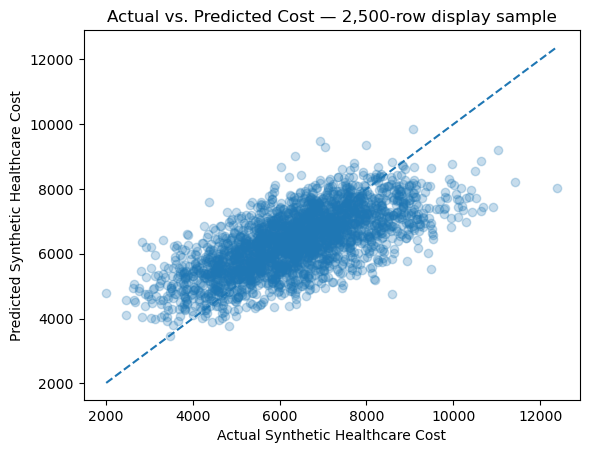

In [158]:
plot_results = results.sample(n=2500, random_state=42)

plt.scatter(
    plot_results['Actual Cost'],
    plot_results['Predicted Cost'],
    alpha=0.25
)

low = min(plot_results['Actual Cost'].min(), plot_results['Predicted Cost'].min())
high = max(plot_results['Actual Cost'].max(), plot_results['Predicted Cost'].max())
plt.plot([low, high], [low, high], '--')

plt.xlabel('Actual Synthetic Healthcare Cost')
plt.ylabel('Predicted Synthetic Healthcare Cost')
plt.title('Actual vs. Predicted Cost — 2,500-row display sample')
plt.show()

### 🧠 Check-In 7

1. What does the diagonal line represent?
2. What does a point far from the line represent?
3. Are the evaluation metrics based only on the 2,500 plotted observations?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 7 — Expected Answer</summary>

1. Perfect agreement: predicted value equals actual value.
2. A larger prediction error.
3. **No.** The plot uses a sample for readability; MAE, RMSE, and R² above were calculated using the full 13,000-row test set.

</details>


<details>
<summary>📝 Note</summary>

**78–86 min.** Ask students to connect visual distance from the line to the concept of error. Be explicit that the plotting sample is not the evaluation sample.

</details>


## 9. Does Adding More Features Automatically Improve a Model?

A tempting assumption is:

> “More columns must create a better model.”

That is not guaranteed.

A feature can be:

- useful signal;
- mostly unrelated noise;
- redundant with other features;
- poorly measured;
- unavailable at prediction time;
- a source of leakage.

The correct question is not “Did we add features?” It is:

> **Did the model perform better on held-out data after we changed the feature set?**

To make a fair comparison, we should evaluate competing models on the **same test observations**.


<details>
<summary>📝 Note</summary>

**Theory emphasis — feature quantity is not feature quality.** Before the exercise, ask students to vote: “More features always help / sometimes help / never help.” Use the disagreement to motivate empirical comparison.

**Fair-comparison rule:** both models must be judged on the same target and the same held-out observations. Otherwise, differences in metrics may partly reflect different test cases rather than model changes.

**Interpretation routine:** require students to state: “Model ___ is better on this test set because its RMSE is ___ versus ___ and its R² is ___ versus ___.” This prevents unsupported statements such as “five features must be better.”

**Broader principle:** a feature can add signal, noise, redundancy, leakage, or operational complexity. Model improvement is an evidence question.

</details>


### ✏️ Your Turn — Build a Smaller Model

Create a regression model using only:

- `age`
- `bmi`

Use the same training and test row indices as our first model. Then compare MAE, RMSE, and R².

Before coding, predict: **Will the smaller model be better, worse, or about the same? Why?**


In [165]:
# Your code here
small_features = ['age', 'bmi']


In [166]:
# SOLUTION — reveal after students try
small_features = ['age', 'bmi']
X_small = health[small_features]

X_small_train = X_small.loc[X_train.index]
X_small_test = X_small.loc[X_test.index]

small_model = LinearRegression()
small_model.fit(X_small_train, y_train)
small_predictions = small_model.predict(X_small_test)

small_mae = mean_absolute_error(y_test, small_predictions)
small_rmse = np.sqrt(mean_squared_error(y_test, small_predictions))
small_r2 = r2_score(y_test, small_predictions)

comparison = pd.DataFrame({
    'Model': ['Age + BMI', 'Five numerical features'],
    'MAE': [small_mae, mae],
    'RMSE': [small_rmse, rmse],
    'R²': [small_r2, r2]
})

comparison.round(3)


,Model,MAE,RMSE,R²
0,Age + BMI,869.987,1092.142,0.432
1,Five numerical features,849.979,1068.836,0.456


### 🧠 Check-In 8

Use the comparison table.

1. Which model has the lower test RMSE?
2. Which has the lower test MAE?
3. Which has the higher test R²?
4. Does this experiment prove that adding features will always improve a model?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 8 — Expected Answer</summary>

Use the generated table for questions 1–3. The correct comparison must cite the **test metrics**, not the number of features. For question 4: **No.** Adding features does not guarantee better generalization.

</details>


<details>
<summary>📝 Note</summary>

**86–96 min.** Give students several minutes to attempt the code. The conceptual objective is fair model comparison, not syntax. Ask every group to justify “better” with at least two test metrics.

</details>


## 10. Categorical Features Need a Numerical Representation

Our initial model did not include `smoker` because it is stored as text (`Yes`/`No`).

`LinearRegression` works with numerical feature values, so categorical information needs a numerical representation before it is passed to this model.

One simple approach for a binary category is **dummy/indicator encoding**.

For example:

```text
smoker
No
Yes
No
```

can be represented by an indicator such as:

```text
smoker_Yes
0
1
0
```

The indicator is not claiming that “Yes equals 1” in an ordinal sense. It is a numerical representation of membership in a category.

Today the important idea is:

> **Different data types may require different preparation before modelling.**


<details>
<summary>📝 Note</summary>

**Theory emphasis — representation, not ranking.** Make clear that converting `Yes` and `No` to an indicator does not mean “Yes is greater than No” in a meaningful numerical scale. The 0/1 values encode category membership for the model.

**Before code:** write three values (`No`, `Yes`, `No`) and ask students how a numerical algorithm could receive the same information. Then reveal the indicator representation.

**Scope control:** students only need the basic idea of encoding today. Do not expand into full one-hot encoding, pipelines, or preprocessing architecture unless needed later in the course.

**After fitting the encoded model:** ask whether the model got a new observation or simply a new representation of an existing variable. Expected: the information was represented numerically; the dataset rows are still the same observations.

</details>


In [172]:
X_encoded = pd.get_dummies(
    health[features + ['smoker']],
    columns=['smoker'],
    drop_first=True,
    dtype=int
)

X_encoded.head()

,age,bmi,systolic_bp,exercise_hours,sleep_hours,smoker_Yes
0,51,23.1,118,2.1,7.6,0
1,31,19.5,88,6.9,6.6,0
2,22,24.2,112,2.2,5.9,0
3,23,31.1,88,4.1,7.7,0
4,49,31.3,132,4.1,7.4,1


### Why `drop_first=True`?

`smoker` has two categories in this synthetic dataset: `No` and `Yes`.

With `drop_first=True`, pandas keeps one indicator column, such as:

```text
smoker_Yes
0
1
0
```

Here:

- `1` means the observation belongs to the `Yes` category;
- `0` means it belongs to the other category, `No`.

For a binary variable, one indicator is enough to represent both possibilities. The omitted category (`No` here) acts as the **reference category**.

This does not mean that `No` is unimportant or that `Yes` is mathematically “greater.” It is simply an efficient numerical representation of category membership for the model.


<details>
<summary>📝 Note</summary>

**Encoding teaching move:** point to a `0` and ask, “Did the information disappear?” Expected: no; zero means the observation belongs to the reference category. Keep the explanation at binary encoding and reference category. Avoid a full dummy-variable-collinearity discussion at this stage.

</details>


### 🧠 Check-In 9

1. What new indicator column represents the smoking category?
2. Why are we creating an indicator rather than passing the original text values directly to this linear-regression workflow?

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 9 — Expected Answer</summary>

1. With these data and `drop_first=True`, the indicator is `smoker_Yes`.
2. The linear-regression estimator expects numerical input features. The indicator provides a numerical representation of the category.

</details>


In [177]:
X_encoded_train = X_encoded.loc[X_train.index]
X_encoded_test = X_encoded.loc[X_test.index]

encoded_model = LinearRegression()
encoded_model.fit(X_encoded_train, y_train)
encoded_predictions = encoded_model.predict(X_encoded_test)

encoded_mae = mean_absolute_error(y_test, encoded_predictions)
encoded_rmse = np.sqrt(mean_squared_error(y_test, encoded_predictions))
encoded_r2 = r2_score(y_test, encoded_predictions)

print(f'Encoded model MAE : ${encoded_mae:,.2f}')
print(f'Encoded model RMSE: ${encoded_rmse:,.2f}')
print(f'Encoded model R²  : {encoded_r2:.3f}')

Encoded model MAE : $719.93
Encoded model RMSE: $903.50
Encoded model R²  : 0.612


<details>
<summary>📝 Note</summary>

**96–102 min.** Keep this focused on data representation. Do not turn the section into a full encoding lecture. Ask: “Did the information change, or did its representation change?”

</details>


## 11. Generalization and Overfitting

Recall the goal from Class Demo 1: **generalization**.

We want a model to learn patterns that remain useful for observations it did not use for training.

### Underfitting

A model may be too limited to capture enough useful pattern. Training and test performance can both be weak.

### Overfitting

A model may learn the training examples too specifically. In that case:

- training performance can look extremely strong;
- test performance can be noticeably worse.

That train-versus-test gap is a warning sign.

### Important idea

> **The best training score is not automatically the best model.**

We care about performance that carries over to new data.

The following tree example is included only to make the idea visible. We are **not** studying decision-tree mechanics today.


<details>
<summary>📝 Note</summary>

**Theory emphasis — training perfection can be suspicious.** Ask: “If a model has almost zero error on every example it studied, should we celebrate immediately?” Expected: not until we know how it performs on unseen/held-out data.

**Read the table horizontally:** for each model, compare its train RMSE with its test RMSE. The unrestricted tree should illustrate an extreme gap. Students should identify the pattern from the numbers before you name it overfitting.

**Contrast the three states:**
- underfitting: poor learning of useful structure;
- generalization: learned structure remains useful on held-out cases;
- overfitting: training-specific detail does not carry over well.

**Do not teach tree mechanics.** The tree exists only as a visual/numerical demonstration of the concept. Bring the discussion immediately back to generalization.

</details>


### Model Complexity: More Flexible Is Not Automatically Better

**Model complexity** or **flexibility** refers to how much freedom a model has to adapt to patterns in the training data.

A model with too little flexibility may **underfit** because it cannot capture enough useful structure.

A highly flexible model may capture more useful structure, but it may also begin to capture training-specific noise or accidental detail. That can lead to **overfitting**.

So the goal is not simply:

> choose the most complex model.

The goal is:

> choose a model whose learned patterns remain useful on data it did not train on.

In the demonstration below, a shallow decision tree has restricted complexity, while an unrestricted tree has much more freedom to adapt to the training observations. We use the two models only to make the relationship between **complexity, training performance, and test performance** visible.


<details>
<summary>📝 Note</summary>

**Before running the tree code:** ask students to predict which tree will achieve the lower *training* error. Then ask the more important question: “Does lower training error guarantee lower test error?” Run the comparison only after students commit to a prediction. The lesson is complexity versus generalization, not tree construction.

</details>


In [183]:
from sklearn.tree import DecisionTreeRegressor

def compare_tree(max_depth, label):
    tree = DecisionTreeRegressor(max_depth=max_depth, random_state=42)
    tree.fit(X_train, y_train)

    train_predictions = tree.predict(X_train)
    test_predictions = tree.predict(X_test)

    return {
        'Model': label,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_predictions)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_predictions))
    }

overfit_demo = pd.DataFrame([
    compare_tree(2, 'Shallow tree'),
    compare_tree(None, 'Unrestricted tree')
])

overfit_demo.round(2)

,Model,Train RMSE,Test RMSE
0,Shallow tree,1244.24,1248.21
1,Unrestricted tree,5.90,1579.82


### 🧠 Check-In 10

Which model shows the stronger warning sign of overfitting? Explain using **both** training RMSE and test RMSE rather than the model name alone.

*Answer before revealing the hidden solution.*

<details>
<summary>✅ Check-In 10 — Expected Answer</summary>

The model with **extremely low training error but substantially higher test error** shows the stronger warning sign. In this generated demonstration, the unrestricted tree is intended to make that train/test gap visible. The explanation should cite the output values.

</details>


<details>
<summary>📝 Note</summary>

**102–107 min.** Keep this to the performance gap. Ask: “If our goal is new observations, which matters more: memorizing training rows or maintaining performance on held-out rows?” Do not teach tree splitting here.

</details>


## 12. What Can We Honestly Say About a Model?

A responsible model summary separates what we measured from what we did **not** establish.

### We can say

- which target was predicted;
- which features were supplied;
- how the historical data were split;
- which algorithm was fitted;
- what performance metrics were observed on the held-out test data;
- how alternative models compared on the same test data.

### We should not automatically say

- the model discovered causes;
- the model is useful in real healthcare settings;
- a synthetic result will generalize to real patients;
- a model with a better training score is necessarily better;
- one metric proves the model is “good.”

Our data are synthetic and were created for learning. The purpose is to understand the machine-learning workflow.


<details>
<summary>📝 Note</summary>

**Theory emphasis — technical results need disciplined language.** Ask students to separate three statement types:
1. statements directly supported by the experiment, such as held-out MAE/RMSE/R²;
2. predictive interpretations, such as one model performing better on this test set;
3. unsupported causal or real-world claims.

**Manager-summary structure:** “We predicted ___ using ___. We evaluated on ___ held-out records. The model achieved ___. Because this is synthetic classroom data, these results demonstrate the workflow rather than real clinical usefulness.”

**Final synthesis:** have students explain the entire workflow without Python vocabulary first. Only afterward ask where `train_test_split`, `.fit()`, `.predict()`, and the metric functions belong. This tests conceptual understanding rather than code recall.

</details>


### 🧠 Final Check-In 11 — Explain the Workflow

Without looking back, put these steps in a sensible order:

- evaluate predictions;
- split historical data;
- define features and target;
- fit the model;
- predict held-out observations.

Then explain in one sentence **why the test set matters**.


<details>
<summary>✅ Check-In 11 — Expected Answer</summary>

A sensible order is:

1. define features and target;
2. split historical data;
3. fit the model using training data;
4. predict held-out observations;
5. evaluate predictions against the known held-out targets.

The test set matters because it provides historical observations that were not used to fit the model, giving us evidence about how well the fitted model generalizes beyond its training examples.

</details>


<details>
<summary>📝 Note</summary>

**107–110 min | Exit ticket.** Ask students to narrate the workflow without code. The best closing evidence of learning is that students can explain *why* split, fit, predict, and evaluate occur in that order.

</details>
